# Informe preliminar — Ruido aerodinámico

## Conjunto C · Matemática IV

**Versión preliminar.** Este notebook reúne los resultados ya cerrados de
EDA, A.1, A.2 y B.5. Las secciones B.1–B.4 y A.3 quedan para la integración
final. Está pensado para ejecutarse de arriba hacia abajo: cada celda de
código llama al script correspondiente de `scripts/` y deja la figura o la
salida numérica lista para visualizar.

**Cómo usarlo.** En Jupyter o Colab: `Runtime → Run all` (o ejecutar las
celdas en orden). La primera celda detecta la raíz del repositorio y prepara
las rutas. Los números no se copian a mano: salen de `src/` y de los scripts.

> Esta versión es de trabajo. No debe tomarse como informe final hasta
> integrar B.1–B.4, A.3 y el Anexo I.


In [1]:
from pathlib import Path
import os
import subprocess
import sys

from IPython.display import Image, display, Markdown


def encontrar_raiz():
    candidatos = [Path.cwd(), *Path.cwd().parents]
    for p in candidatos:
        if (p / "src" / "data_loader.py").exists():
            return p
        for hijo in p.glob("*/src/data_loader.py"):
            return hijo.parents[1]
    raise FileNotFoundError(
        "No encuentro la raíz del repo. Abrir el notebook desde el repo "
        "o desde notebooks/."
    )


ROOT = encontrar_raiz()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


def correr(modulo):
    r = subprocess.run(
        [sys.executable, "-m", modulo],
        cwd=ROOT,
        capture_output=True,
        text=True,
    )
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr)
        raise RuntimeError(f"Falló {modulo}")
    return r


def mostrar_figura(ruta):
    display(Image(filename=str(ROOT / ruta)))


print("Raíz del repo:", ROOT)


Raíz del repo: /home/santi/Documentos/mateIV


## 1. Datos y variables

El conjunto de datos UCI *Airfoil Self-Noise* contiene $n=1503$ mediciones
de ruido aerodinámico. Cada fila corresponde a una combinación de frecuencia,
ángulo de ataque, longitud de cuerda, velocidad y espesor de desplazamiento,
junto con el nivel de presión sonora medido.

| Variable | Símbolo | Unidad | Papel en el TP |
|---|---|---:|---|
| `frequency` | $x$ | Hz | regresor principal de A.1 y A.2 |
| `angle` | $x_2$ | grados | regresor de B.5 |
| `chord_length` | $x_3$ | m | regresor de B.5 |
| `velocity` | — | m/s | solo EDA; excluida de B.2 y B.5 |
| `displacement` | $x_4$ | m | regresor de B.5 |
| `sound_level` | $y$ | dB | respuesta |

La variable `velocity` tiene solo cuatro valores y la consigna la excluye de
las rectas simples y de la regresión múltiple. Se describe únicamente en el
EDA.

La carga y la validación de forma/rangos las hace `src/data_loader.py`.


In [2]:
from src.data_loader import load_airfoil

df = load_airfoil("data/airfoil_self_noise.dat")
print(f"n = {len(df)}; columnas = {list(df.columns)}")
display(df.head())


n = 1503; columnas = ['frequency', 'angle', 'chord_length', 'velocity', 'displacement', 'sound_level']


,frequency,angle,chord_length,velocity,displacement,sound_level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


## 2. Análisis exploratorio

Antes de ajustar cualquier modelo conviene mirar las escalas, los valores
discretos y la forma de las distribuciones. Esto explica por qué A.3 exige
normalizar: `frequency` se mueve en miles de Hz y `displacement` en
fracciones de milímetro.

La siguiente celda ejecuta el EDA completo y deja lista la figura con los
seis histogramas.


EDA — Airfoil Self-Noise (n = 1503)

Descriptivos:
              count      mean       std         min        25%        50%       75%       max
frequency      1503   2886.38   3152.57         200        800       1600      4000     20000
angle          1503    6.7823   5.91813           0          2        5.4       9.9      22.2
chord_length   1503  0.136548 0.0935407      0.0254     0.0508     0.1016    0.2286    0.3048
velocity       1503   50.8607   15.5728        31.7       39.6       39.6      71.3      71.3
displacement   1503 0.0111399 0.0131502 0.000400682 0.00253511 0.00495741 0.0155759 0.0584113
sound_level    1503   124.836   6.89866      103.38    120.191    125.721   129.995   140.987

Variables con pocos valores distintos:
frequency: 21 valores -> [200, 250, 315, 400, 500, 630, 800, 1000, 1250, 1600, 2000, 2500, 3150, 4000, 5000, 6300, 8000, 10000, 12500, 16000, 20000]
angle: 27 valores -> [0.0, 1.5, 2.0, 2.7, 3.0, 3.3, 4.0, 4.2, 4.8, 5.3, 5.4, 6.7, 7.2, 7.3, 8.4, 8.9, 

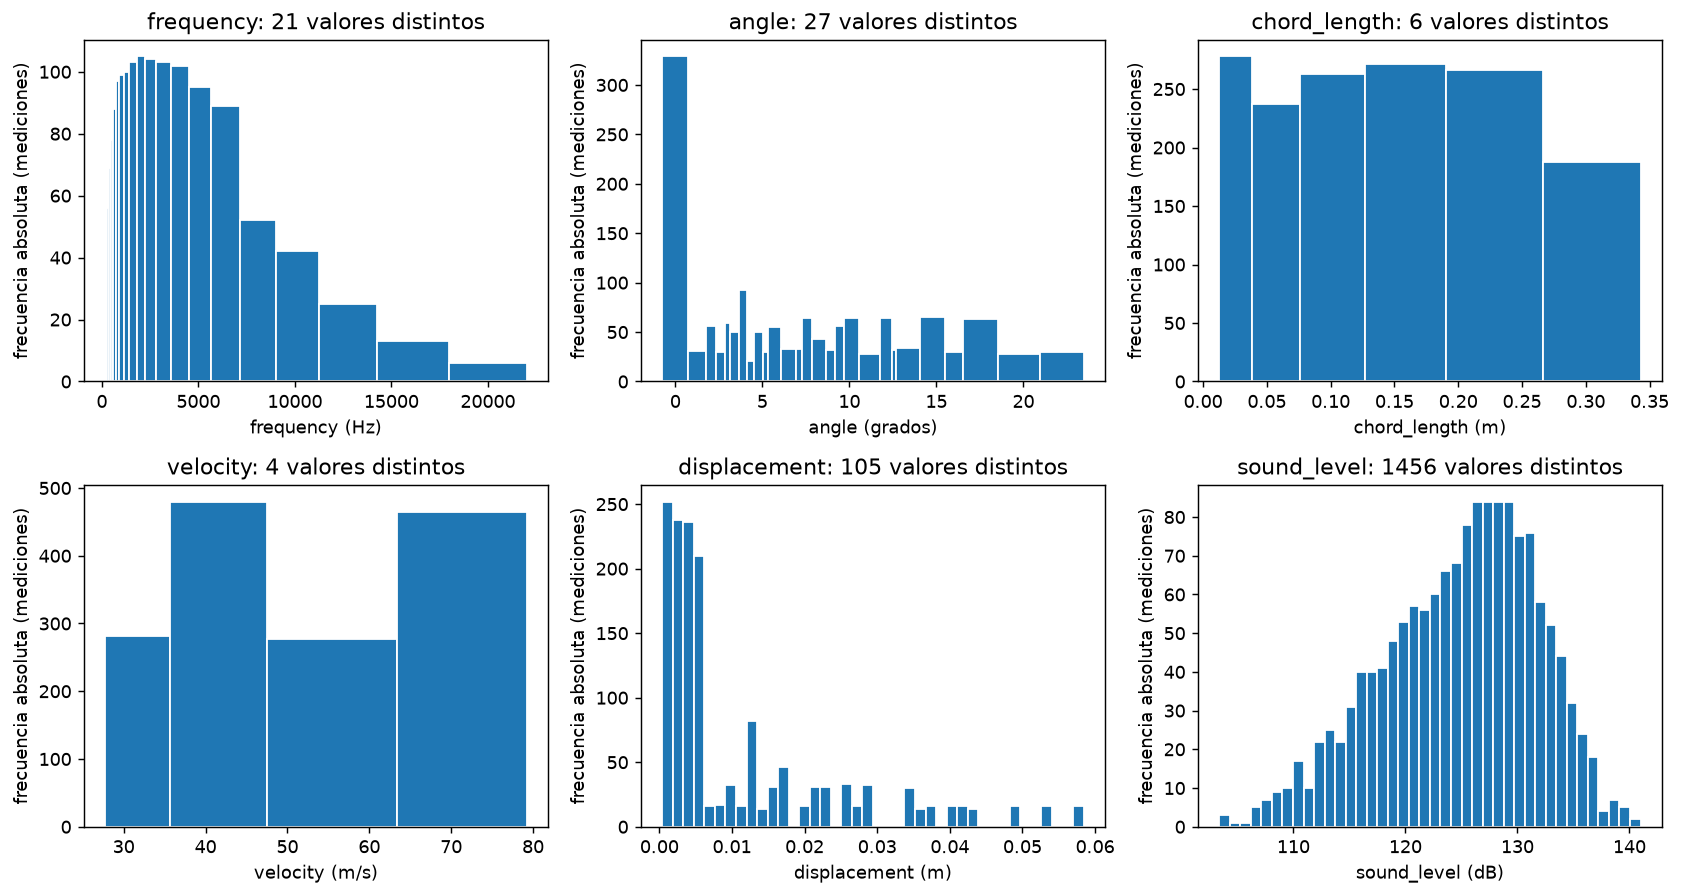

In [3]:
correr("scripts.eda")
mostrar_figura("docs/figs/eda_histogramas.png")


### Lectura del EDA

- **frequency (Hz):** tiene 21 valores distintos, espaciados aproximadamente
  en forma logarítmica. Hay muchas más mediciones en frecuencias bajas; la
  cola de 10–20 kHz es escasa.
- **angle (grados):** 27 valores, concentrados entre 0 y 5 grados. Los ángulos
  altos tienen pocas observaciones y pueden influir puntualmente en los
  ajustes.
- **chord_length (m):** 6 valores entre 0.0254 y 0.3048 m, razonablemente
  cubiertos.
- **velocity (m/s):** 4 valores: 31.7, 39.6, 55.5 y 71.3 m/s. Se describe
  solo como caracterización experimental.
- **displacement (m):** distribución asimétrica a la derecha, con la mayoría
  de los datos por debajo de 0.01 m y una cola hasta 0.058 m.
- **sound_level (dB):** se concentra alrededor de 125 dB, con rango observado
  de 103.4 a 141.0 dB.

La figura muestra conteos por valor distinto en las variables discretas y
histogramas en las continuas. No debe interpretarse como densidad suavizada.


## 3. A.1 — Ajuste cuadrático de `sound_level` en `frequency`

Se propone el modelo

$$
\widehat{y}(x)=b_0+b_1x+b_2x^2,
$$

donde $x=$ `frequency` (Hz) e $y=$ `sound_level` (dB). Los coeficientes se
estiman por mínimos cuadrados, minimizando

$$
SCE(b_0,b_1,b_2)=\sum_{i=1}^{n}\left(y_i-b_0-b_1x_i-b_2x_i^2\right)^2.
$$

La derivada es

$$
\frac{d\widehat{y}}{dx}=b_1+2b_2x \qquad (\text{dB/Hz}),
$$

y el punto crítico se obtiene de $d\widehat{y}/dx=0$:

$$
x^*=-\frac{b_1}{2b_2}.
$$

La segunda derivada $d^2\widehat{y}/dx^2=2b_2$ decide si es mínimo
($b_2>0$) o máximo ($b_2<0$). La comparación con la recta de A.2 se hace
con $R^2$ y $SCE$.

La celda siguiente ajusta el modelo, calcula derivadas y punto crítico, y
deja lista la figura con la curva y los residuos.


cuadratico: b0=128.3104 dB  b1=-1.561198e-03 dB/Hz  b2=5.649251e-08 dB/Hz2
lineal:     bl0=127.3037 dB  bl1=-8.549790e-04 dB/Hz
dy/dx en x=1000 Hz = -1.448213e-03 dB/Hz  (~-0.145 dB cada 100 Hz)
dy/dx en x=10000 Hz = -4.313479e-04 dB/Hz  (~-0.043 dB cada 100 Hz)
critico x*=13817.7 Hz  y*=117.52 dB  2da deriv.=1.130e-07  (minimo)  dentro [200,20000]: True
R2 cuadr.=0.1734 (SCE=59090.2)  R2 lin.=0.1527 (SCE=60570.2)
figura: docs/figs/a1_aproximacion.png



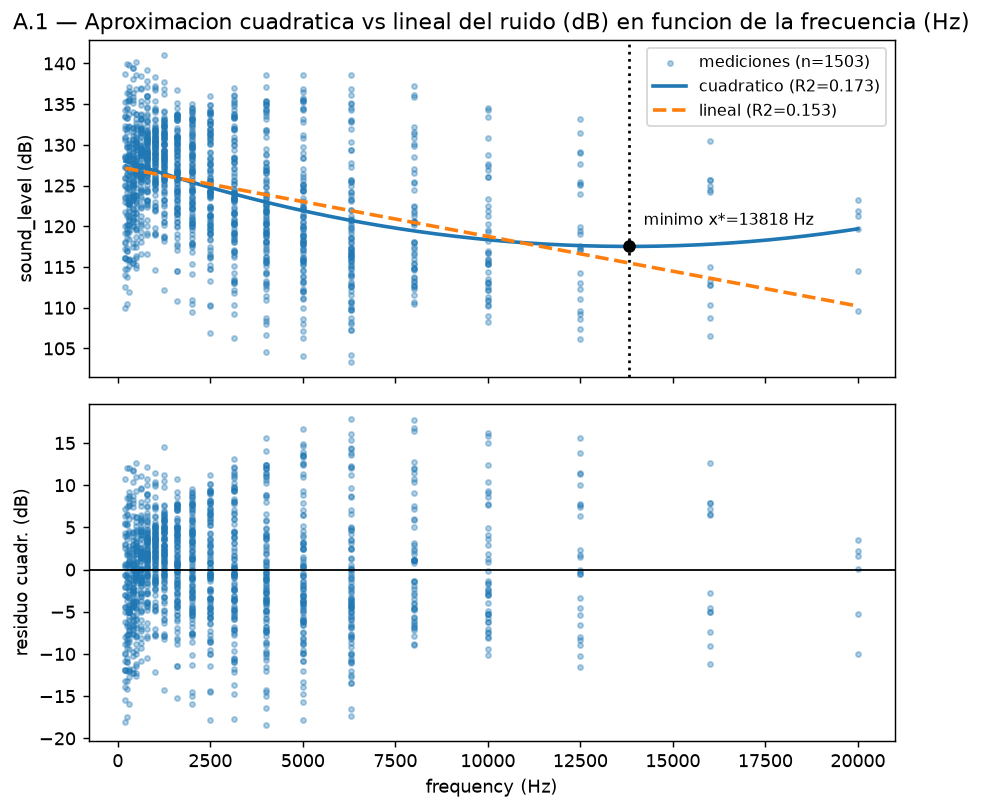

In [4]:
correr("scripts.a1_cuadratico")
mostrar_figura("docs/figs/a1_aproximacion.png")


### Lectura de A.1

- Los coeficientes y sus unidades aparecen en la salida: $b_0$ en dB,
  $b_1$ en dB/Hz y $b_2$ en dB/Hz².
- La derivada es más negativa a 1 kHz que a 10 kHz: el ruido cae rápido al
  principio y la curva se aplana en frecuencias altas.
- El punto crítico cae dentro de $[200,20000]$ Hz y la segunda derivada es
  positiva, así que es un **mínimo**. La zona de 12–20 kHz tiene pocos datos:
  el mínimo es una tendencia interpolada, no una extrapolación fuerte.
- El $R^2$ cuadrático supera apenas al lineal. La frecuencia sola explica
  una fracción chica de la variabilidad; la dispersión de los residuos sigue
  siendo grande. Eso motiva el modelo múltiple de B.5.

El ajuste es descriptivo: no prueba causalidad ni reemplaza la inferencia de
B.3.


## 4. A.2 — Derivadas parciales y ecuaciones normales

Para la recta $\widehat{y}=b_0+b_1x$, la suma de cuadrados es

$$
SCE(b_0,b_1)=\sum_{i=1}^{n}\left(y_i-b_0-b_1x_i\right)^2.
$$

Sus derivadas parciales son

$$
\frac{\partial SCE}{\partial b_0}
=-2\sum_i\left(y_i-b_0-b_1x_i\right),
\qquad
\frac{\partial SCE}{\partial b_1}
=-2\sum_i x_i\left(y_i-b_0-b_1x_i\right).
$$

Igualando a cero se obtiene el sistema normal

$$
n b_0+\left(\sum_i x_i\right)b_1=\sum_i y_i,
\qquad
\left(\sum_i x_i\right)b_0+\left(\sum_i x_i^2\right)b_1=\sum_i x_iy_i.
$$

Resolviendo:

$$
b_1=\frac{S_{xy}}{S_{xx}},
\qquad
b_0=\bar y-b_1\bar x.
$$

La celda compara tres caminos: sistema normal, fórmulas cerradas de
`src/metrics.py` y `numpy.polyfit`.


In [5]:
_ = correr("scripts.a2_normales")


A.2 — Parciales y ecuaciones normales (frequency -> sound_level)
n = 1503
Σx  = 4.338230e+06 Hz
Σy  = 1.876284e+05 dB
Σx² = 2.744974e+10 Hz²
Σxy = 5.288039e+08 Hz·dB

Sistema normal A·[b0, b1]ᵀ = d:
[[1.50300000e+03 4.33823000e+06]
 [4.33823000e+06 2.74497363e+10]]
d = [1.87628422e+05 5.28803945e+08]

Solución del sistema: b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
Fórmulas cerradas:    b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
Desde sumatorias:     b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
numpy.polyfit:        b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz

|normal - cerrada| = (1.421e-14, 1.084e-18)
|normal - polyfit| = (4.263e-14, 4.228e-18)
Gradiente en el óptimo = [1.22781785e-11 9.31322575e-09]

Recta: sound_level = 127.3037 dB -8.549790e-04 dB/Hz · frequency



### Lectura de A.2

- El sistema normal, las fórmulas cerradas y `polyfit` coinciden hasta el
  orden del error de redondeo; las diferencias que muestra la salida son del
  orden de $10^{-14}$ o menores.
- El gradiente de $SCE$ en el óptimo es prácticamente nulo, como exige la
  condición de primer orden.
- La pendiente es negativa: en el ajuste lineal simple, aumentar la frecuencia
  se asocia con menor nivel de ruido. La ordenada al origen tiene unidades de
  dB y la pendiente de dB/Hz.
- Esta recta es la referencia lineal que después se compara con el ajuste
  cuadrático de A.1 y con las rectas de B.2.


## 5. B.5 — Regresión múltiple

Se usa el modelo

$$
y=\beta_0+\beta_1\,frequency+\beta_2\,angle
+\beta_3\,chord\_length+\beta_4\,displacement+\varepsilon,
$$

con `velocity` excluida. En forma matricial, $y=X\beta+\varepsilon$ y

$$
\widehat{\beta}=(X^\top X)^{-1}X^\top y.
$$

La bondad de ajuste se compara con el $R^2$ ajustado:

$$
R^2_{aj}=1-(1-R^2)\frac{n-k}{n-k-1},
\qquad n=1503,\ k=4.
$$

La celda ajusta el modelo y deja lista una figura de observado vs predicho.


B.5 — Regresión múltiple (velocity excluida)
coeficiente              valor  unidad
intercepto        1.371276e+02  dB
frequency        -1.196133e-03  dB/Hz
angle            -3.515654e-01  dB/grado
chord_length     -3.388729e+01  dB/m
displacement     -1.640449e+02  dB/m
R2 = 0.4669   R2 ajustado = 0.4666
figura: docs/figs/b5_predicho_observado.png



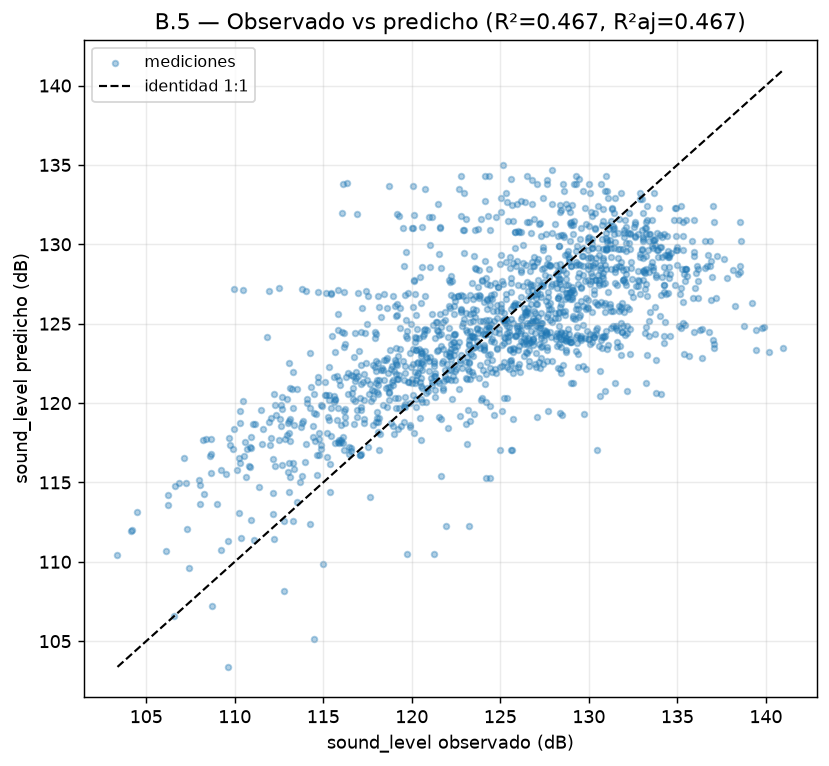

In [6]:
correr("scripts.b5_multiple")
mostrar_figura("docs/figs/b5_predicho_observado.png")


### Lectura de B.5

- El $R^2$ ajustado ronda 0.47, frente a aproximadamente 0.15 del mejor
  modelo simple con frecuencia. El modelo múltiple explica cerca del triple,
  pero todavía deja más de la mitad de la variabilidad sin explicar.
- En este ajuste conjunto, los coeficientes de las cuatro variables son
  negativos. Deben interpretarse con cautela: las variables están
  correlacionadas entre sí y un coeficiente negativo no implica una relación
  causal aislada.
- La figura de observado vs predicho muestra una nube alrededor de la
  identidad, pero con dispersión de varios dB. El modelo captura la tendencia
  central, no los casos individuales.
- Falta la inferencia formal: B.3 (test $H_0:\beta_1=0$) y B.4 (intervalos
  de confianza y predicción en $x^*=2000$ Hz) todavía no están integradas.

La solución exacta de B.5 se calcula con `src/multiple.py`; no se usa
`sklearn`.


## 6. Síntesis preliminar

**Lo que ya se puede afirmar.**

- El EDA muestra escalas muy distintas entre variables, valores discretos en
  frecuencia, cuerda y velocidad, y una respuesta aproximadamente centrada en
  125 dB.
- A.1 y A.2 muestran que la frecuencia sola explica una fracción chica del
  ruido (alrededor de 15–17 %). El ajuste cuadrático agrega curvatura, pero la
  mejora es modesta.
- B.5 mejora sustancialmente la explicación (cerca de 47 % ajustado), aunque
  la dispersión residual sigue siendo importante.
- La comparación entre métodos (sistema normal, fórmulas cerradas y
  `polyfit`) valida la implementación numérica.

**Limitaciones de esta versión.**

- No están integradas B.1 (varianza e intervalos), B.2 (cuatro rectas),
  B.3 (test de hipótesis y scatter) ni B.4 (ICM/IP en $x^*=2000$ Hz).
- A.3 (descenso por gradiente) está en desarrollo por otra integrante y se
  excluyó deliberadamente de esta rama.
- El informe final debe revisar que todos los números coincidan entre bloques
  y agregar el Anexo I.


## 7. Reproducibilidad

Todos los resultados se regeneran desde la raíz del repositorio:

```bash
python -m scripts.eda
python -m scripts.a1_cuadratico
python -m scripts.a2_normales
python -m scripts.b5_multiple
```

Los tests numéricos se corren con:

```bash
pip install pytest
python -m pytest -q
```

Para exportar a PDF se puede usar `jupyter nbconvert --to pdf
notebooks/informe.ipynb` o imprimir el notebook desde el navegador.


In [7]:
try:
    import pytest
    r = subprocess.run(
        [sys.executable, "-m", "pytest", "-q", "--color=no"],
        cwd=ROOT,
        capture_output=True,
        text=True,
    )
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr)
except ImportError:
    print("pytest no está instalado; ejecutar: pip install pytest")


.......................................                                  [100%]
39 passed in 0.78s



## 8. Trabajo pendiente para la versión final

| Bloque | Contenido | Estado |
|---|---|---|
| B.1 | tabla STC = SCR + SCE, $\sigma^2$, $R^2$ | pendiente |
| B.2 | tabla de las 4 rectas simples | pendiente |
| B.3 | test $H_0:\beta_1=0$ + scatter | pendiente |
| B.4 | ICM e IP al 95 % en $x^*=2000$ Hz | pendiente |
| A.3 | gradiente con 3 $\alpha$ | en desarrollo |
| Integración | PDF ≤ 20 páginas, Colab y coherencia | pendiente |
| Anexo I | bitácora de interacciones con IA | pendiente |

La prioridad matemática es cerrar B.1–B.4 para que el informe tenga
inferencia completa: estimación, intervalos, test de hipótesis y comparación
de modelos. La prioridad de integración es verificar que los $\beta$, $R^2$,
$n$ y $x^*$ coincidan entre bloques.

## Anexo I — Bitácora IA (pendiente)

Este anexo se completa en la integración final (t0-6), registrando pedido,
respuesta, decisión y sección afectada para cada interacción con asistentes
de IA.
